In [1]:
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from shared.paths import load_paths
paths = load_paths()

In [2]:
ROOT = Path(paths.cp4_2d) / "CP4_box_JASMIN/mean3h_v2/timeseries"

storm_files = sorted(glob.glob(str(ROOT / "storm_event_summary_*.csv")))
event_files = sorted(glob.glob(str(ROOT / "all_wetting_drydown_events_*.csv")))

storm_file = storm_files[-1]
event_file = event_files[-1]

print("Storm summary:", Path(storm_file).name)
print("Event table:  ", Path(event_file).name)

storm = pd.read_csv(storm_file)
events = pd.read_csv(event_file)

print(storm.shape, events.shape)
display(storm.head())
display(events.head())

Storm summary: storm_event_summary_Aug08_hours171819_SMwet2p5_Rain5p0mm_Dry2p5_gap12h_pm30d_box23px.csv
Event table:   all_wetting_drydown_events_Aug08_hours171819_SMwet2p5_Rain5p0mm_Dry2p5_gap12h_pm30d_box23px.csv
(16413, 42) (512817, 17)


,label,hour,file,storm_time,storm_lon,storm_lat,t0_SM_before,t0_SM_after,t0_dSM,t0_rain_m5_p5,...,rain_t0_event_dSM,rain_t0_event_rain_mm,rain_t0_max_drydown,rain_t0_drydown_ge_2p5,rain_t0_hours_to_dry_2p5,rain_next_event_lag_h,rain_next_event_dSM,rain_next_event_rain_mm,rain_days_prev_to_t0,rain_days_t0_to_next
0,hist,17,1998-08-01_17:00:00_103_lonXlat_[-10.6]_[13.]_...,1998-08-01 17:00:00,-10.648987,12.957001,11.200139,13.061223,1.861084,3.771759,...,NaN,NaN,NaN,False,NaN,76.0,3.507076,5.578404,NaN,NaN
1,hist,17,1998-08-01_17:00:00_104_lonXlat_[2.6]_[13.3]_3...,1998-08-01 17:00:00,2.554016,13.321503,7.924443,18.205757,10.281314,22.071195,...,10.281314,22.078616,2.863875,True,14.0,85.0,5.180933,7.853385,2.958333,3.583333
2,hist,17,1998-08-01_17:00:00_115_lonXlat_[15.6]_[14.]_3...,1998-08-01 17:00:00,15.595001,14.010002,9.455621,12.899578,3.443957,6.514561,...,3.443957,6.514561,9.615374,True,18.0,144.0,6.175783,9.806105,1.875000,6.000000
3,hist,17,1998-08-01_17:00:00_116_lonXlat_[8.9]_[14.5]_3...,1998-08-01 17:00:00,8.912506,14.496002,11.006702,15.165546,4.158844,8.820254,...,4.158844,8.820254,10.763044,True,18.0,441.0,8.753657,19.966957,3.833333,18.375000
4,hist,17,1998-08-01_17:00:00_124_lonXlat_[2.1]_[15.7]_3...,1998-08-01 17:00:00,2.148987,15.711002,7.802064,13.172253,5.370188,8.910278,...,5.370188,8.910278,10.147132,True,18.0,193.0,3.954347,6.947307,3.041667,8.000000


,label,hour,file,definition,event_lag_h,event_group_start_lag_h,event_group_end_lag_h,SM_before,SM_after,dSM,rain_accum_m5_p5,max_drydown,drydown_ge_2p5,hours_to_dry_2p5,days_to_dry_2p5,next_event_lag_h,hours_to_next_event
0,hist,17,1998-08-01_17:00:00_103_lonXlat_[-10.6]_[13.]_...,SM>=2.5,-682.0,-685.0,-674.0,16.849054,30.399904,13.550850,28.191234,18.759300,True,5.0,0.208333,-571.0,111.0
1,hist,17,1998-08-01_17:00:00_103_lonXlat_[-10.6]_[13.]_...,SM>=2.5,-571.0,-575.0,-565.0,11.640604,17.473316,5.832712,11.868106,4.282198,True,11.0,0.458333,-547.0,24.0
2,hist,17,1998-08-01_17:00:00_103_lonXlat_[-10.6]_[13.]_...,SM>=2.5,-547.0,-551.0,-540.0,13.191118,22.096951,8.905832,15.070588,5.015993,True,10.0,0.416667,-517.0,30.0
3,hist,17,1998-08-01_17:00:00_103_lonXlat_[-10.6]_[13.]_...,SM>=2.5,-517.0,-520.0,-510.0,17.080957,26.836626,9.755669,22.544859,15.874081,True,6.0,0.250000,-401.0,116.0
4,hist,17,1998-08-01_17:00:00_103_lonXlat_[-10.6]_[13.]_...,SM>=2.5,-401.0,-410.0,-393.0,12.877472,30.049171,17.171700,44.424890,20.589231,True,6.0,0.250000,-205.0,196.0


In [3]:
events["definition_plot"] = events["definition"].replace({
    "SM>=2.5": r"SM wetting ≥2.5 kg m$^{-2}$",
    "Rain>=5mm": "Rain ≥5 mm",
})

LABELS = ["hist", "future"]
DEFS = ["SM>=2.5", "Rain>=5mm"]

In [4]:
freq = pd.concat([
    storm[["label", "file", "n_SM_events"]]
        .rename(columns={"n_SM_events": "n_events"})
        .assign(definition="SM-defined"),

    storm[["label", "file", "n_rain_events"]]
        .rename(columns={"n_rain_events": "n_events"})
        .assign(definition="Rain-defined"),
], ignore_index=True)

display(
    freq.groupby(["label", "definition"])["n_events"]
        .agg(["count", "mean", "median", "std"])
)

count       mean  median       std
label  definition                                      
future Rain-defined   6943  14.474291    15.0  5.127377
       SM-defined     6943  14.043641    14.0  4.344131
hist   Rain-defined   9470  16.758923    17.0  6.318563
       SM-defined     9470  16.484688    17.0  5.246136

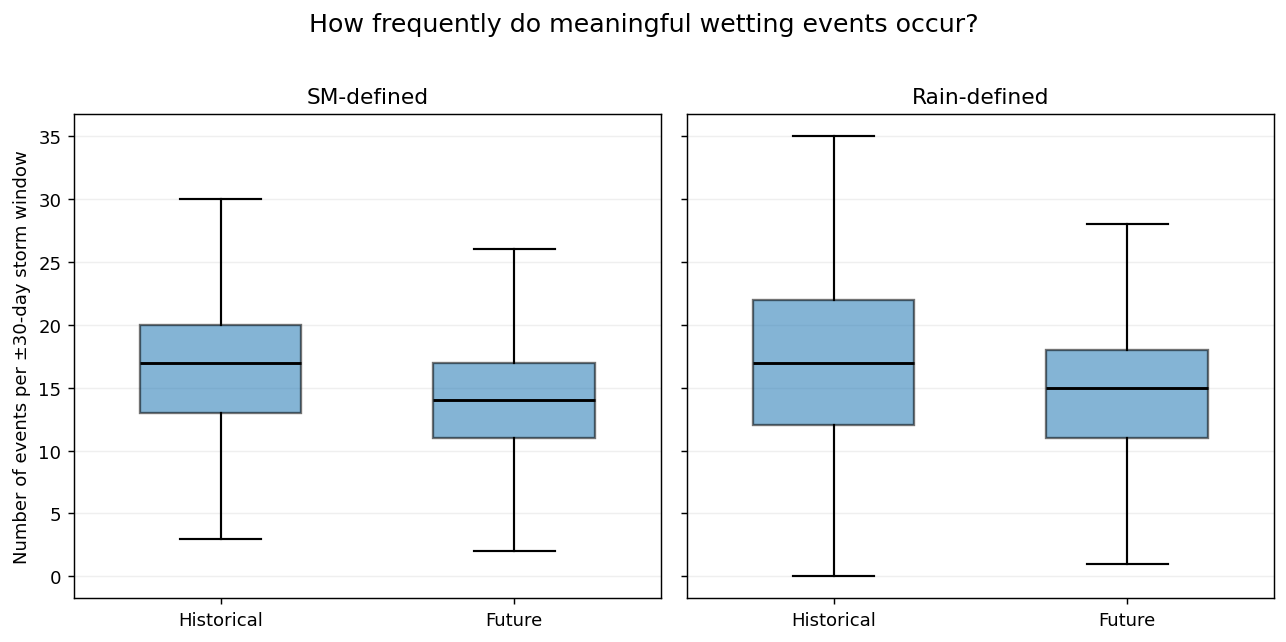

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), dpi=130, sharey=True)

for ax, definition in zip(axes, ["SM-defined", "Rain-defined"]):
    h = freq[
        (freq["definition"] == definition) &
        (freq["label"] == "hist")
    ]["n_events"].dropna()

    f = freq[
        (freq["definition"] == definition) &
        (freq["label"] == "future")
    ]["n_events"].dropna()

    bp = ax.boxplot(
        [h, f],
        positions=[1, 2],
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.6},
        boxprops={"linewidth": 1.3},
        whiskerprops={"linewidth": 1.2},
        capprops={"linewidth": 1.2},
    )

    for patch, alpha in zip(bp["boxes"], [0.55, 0.55]):
        patch.set_alpha(alpha)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Historical", "Future"])
    ax.set_title(definition)
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel("Number of events per ±30-day storm window")

fig.suptitle(
    "How frequently do meaningful wetting events occur?",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

In [6]:
events["days_to_next_event"] = events["hours_to_next_event"] / 24
inter = events[
    np.isfinite(events["days_to_next_event"]) &
    (events["days_to_next_event"] > 0)
].copy()
display(
    inter.groupby(["label", "definition"])["days_to_next_event"]
         .agg(["count", "mean", "median",
               lambda x: np.nanpercentile(x, 25),
               lambda x: np.nanpercentile(x, 75)])
)

count      mean    median  <lambda_0>  <lambda_1>
label  definition                                                    
future Rain>=5mm    93554  3.845478  3.166667    2.000000    4.958333
       SM>=2.5      90564  3.997499  3.375000    2.083333    5.125000
hist   Rain>=5mm   149240  3.263550  2.666667    1.750000    4.041667
       SM>=2.5     146641  3.376395  2.833333    1.833333    4.291667

In [7]:
spacing_summary = (
    inter.groupby(["label", "definition"])
    .agg(
        n=("days_to_next_event", "size"),
        median_days=("days_to_next_event", "median"),
        p25_days=("days_to_next_event", lambda x: np.nanpercentile(x, 25)),
        p75_days=("days_to_next_event", lambda x: np.nanpercentile(x, 75)),
    )
    .reset_index()
)

display(spacing_summary)

,label,definition,n,median_days,p25_days,p75_days
0,future,Rain>=5mm,93554,3.166667,2.000000,4.958333
1,future,SM>=2.5,90564,3.375000,2.083333,5.125000
2,hist,Rain>=5mm,149240,2.666667,1.750000,4.041667
3,hist,SM>=2.5,146641,2.833333,1.833333,4.291667


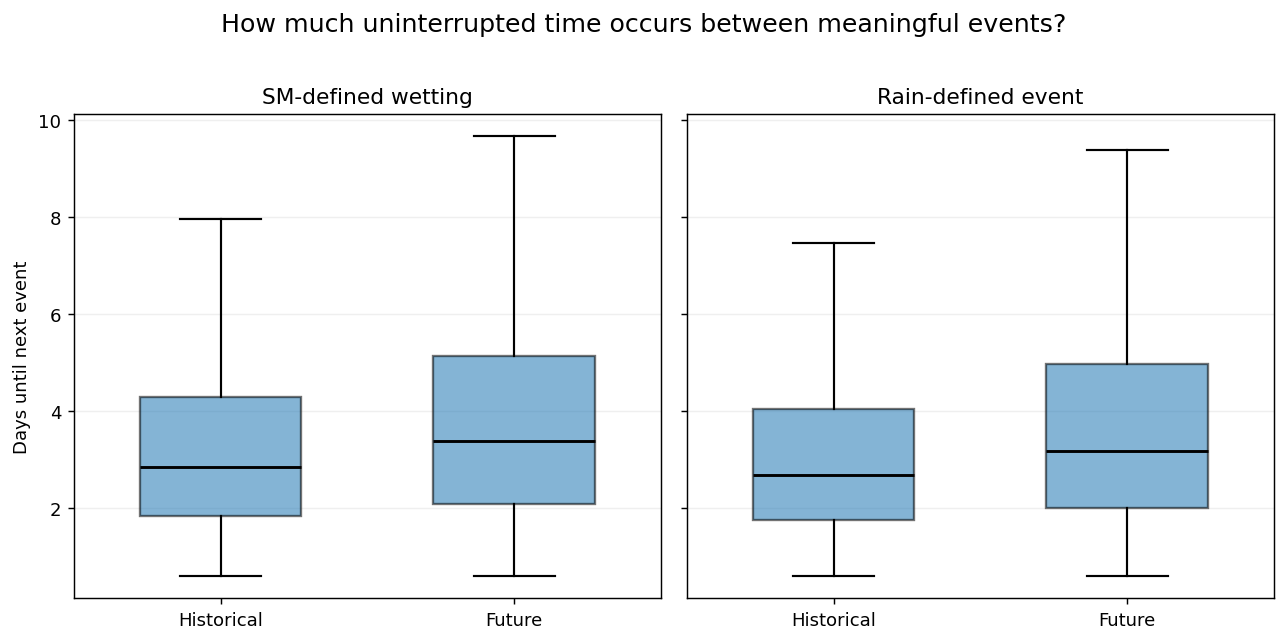

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), dpi=130, sharey=True)

for ax, definition, title in zip(
    axes,
    DEFS,
    ["SM-defined wetting", "Rain-defined event"]
):
    h = inter[
        (inter["definition"] == definition) &
        (inter["label"] == "hist")
    ]["days_to_next_event"].dropna()

    f = inter[
        (inter["definition"] == definition) &
        (inter["label"] == "future")
    ]["days_to_next_event"].dropna()

    bp = ax.boxplot(
        [h, f],
        positions=[1, 2],
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.6},
        boxprops={"linewidth": 1.3},
        whiskerprops={"linewidth": 1.2},
        capprops={"linewidth": 1.2},
    )

    for patch in bp["boxes"]:
        patch.set_alpha(0.55)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Historical", "Future"])
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel("Days until next event")

fig.suptitle(
    "How much uninterrupted time occurs between meaningful events?",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

In [9]:
dry = events[
    np.isfinite(events["hours_to_next_event"])
].copy()

dry["drydown_ge_2p5"] = dry["drydown_ge_2p5"].astype(bool)

In [10]:
dry_fraction = (
    dry.groupby(["label", "definition"])
    .agg(
        n_events=("drydown_ge_2p5", "size"),
        n_dry_ge2p5=("drydown_ge_2p5", "sum"),
        fraction=("drydown_ge_2p5", "mean"),
    )
    .reset_index()
)

dry_fraction["percent"] = dry_fraction["fraction"] * 100

display(dry_fraction)

,label,definition,n_events,n_dry_ge2p5,fraction,percent
0,future,Rain>=5mm,93554,83683,0.894489,89.448874
1,future,SM>=2.5,90564,81821,0.903461,90.346054
2,hist,Rain>=5mm,149240,131392,0.880407,88.040740
3,hist,SM>=2.5,146641,130926,0.892834,89.283352


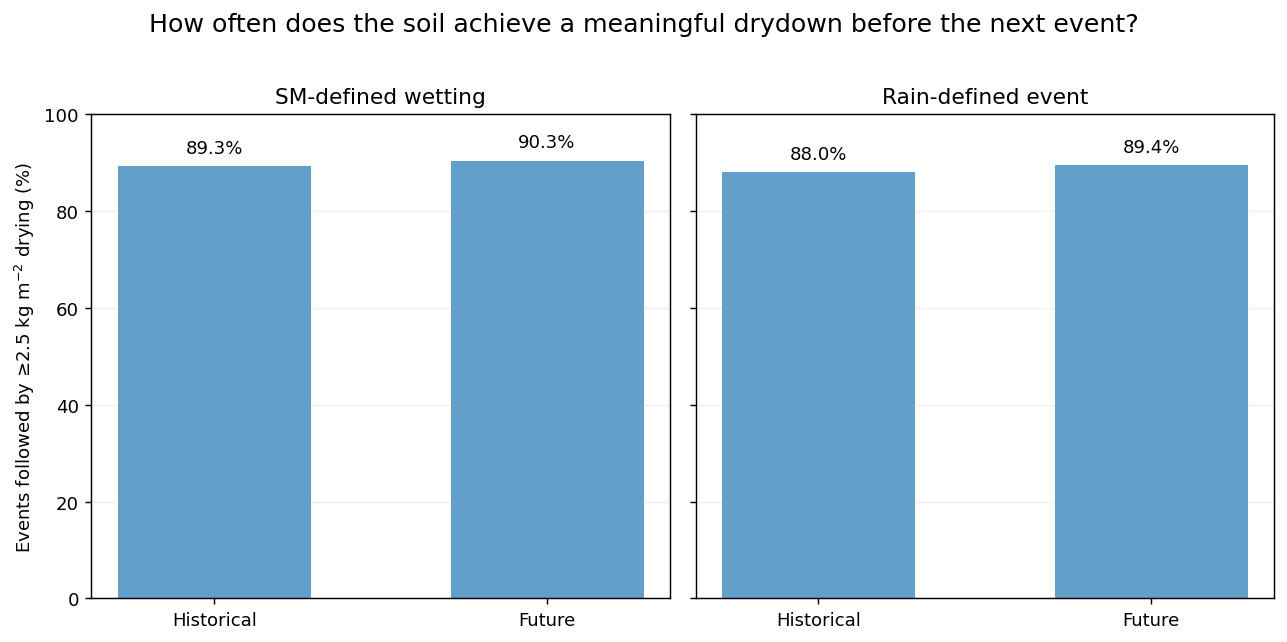

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), dpi=130, sharey=True)

for ax, definition, title in zip(
    axes,
    DEFS,
    ["SM-defined wetting", "Rain-defined event"]
):
    s = dry_fraction[dry_fraction["definition"] == definition]

    vals = [
        s.loc[s["label"] == "hist", "percent"].iloc[0],
        s.loc[s["label"] == "future", "percent"].iloc[0],
    ]

    bars = ax.bar(
        [0, 1],
        vals,
        width=0.58,
        alpha=0.7,
    )

    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Historical", "Future"])
    ax.set_title(title)
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.2)

    for bar, val in zip(bars, vals):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            val + 2,
            f"{val:.1f}%",
            ha="center",
            va="bottom",
            fontsize=10,
        )

axes[0].set_ylabel(
    "Events followed by ≥2.5 kg m$^{-2}$ drying (%)"
)

fig.suptitle(
    "How often does the soil achieve a meaningful drydown before the next event?",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

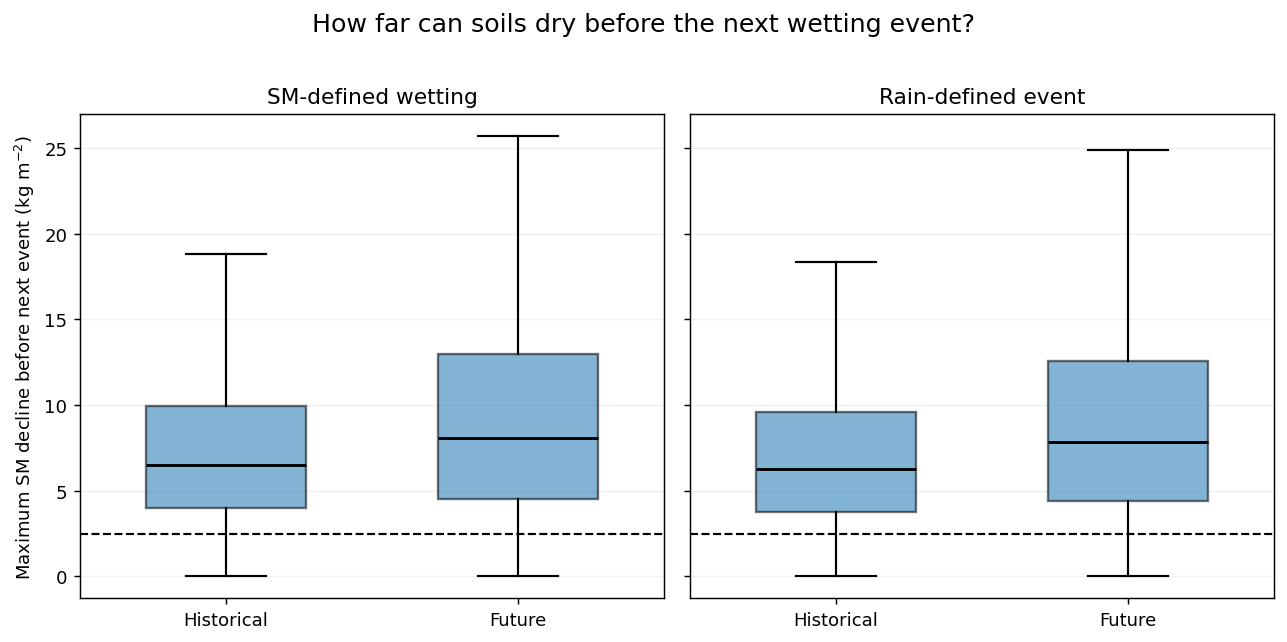

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), dpi=130, sharey=True)

for ax, definition, title in zip(
    axes,
    DEFS,
    ["SM-defined wetting", "Rain-defined event"]
):
    h = dry[
        (dry["definition"] == definition) &
        (dry["label"] == "hist")
    ]["max_drydown"].dropna()

    f = dry[
        (dry["definition"] == definition) &
        (dry["label"] == "future")
    ]["max_drydown"].dropna()

    bp = ax.boxplot(
        [h, f],
        positions=[1, 2],
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.6},
        boxprops={"linewidth": 1.3},
        whiskerprops={"linewidth": 1.2},
        capprops={"linewidth": 1.2},
    )

    for patch in bp["boxes"]:
        patch.set_alpha(0.55)

    ax.axhline(2.5, color="k", ls="--", lw=1.2)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Historical", "Future"])
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel(
    r"Maximum SM decline before next event (kg m$^{-2}$)"
)

fig.suptitle(
    "How far can soils dry before the next wetting event?",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

In [13]:
reached = dry[
    dry["drydown_ge_2p5"] &
    np.isfinite(dry["days_to_dry_2p5"])
].copy()

In [14]:
drytime_summary = (
    reached.groupby(["label", "definition"])
    .agg(
        n=("days_to_dry_2p5", "size"),
        median_days=("days_to_dry_2p5", "median"),
        p25_days=("days_to_dry_2p5", lambda x: np.nanpercentile(x, 25)),
        p75_days=("days_to_dry_2p5", lambda x: np.nanpercentile(x, 75)),
    )
    .reset_index()
)

display(drytime_summary)

,label,definition,n,median_days,p25_days,p75_days
0,future,Rain>=5mm,83683,0.583333,0.333333,0.833333
1,future,SM>=2.5,81821,0.583333,0.333333,0.833333
2,hist,Rain>=5mm,131392,0.583333,0.375000,0.833333
3,hist,SM>=2.5,130926,0.583333,0.375000,0.833333


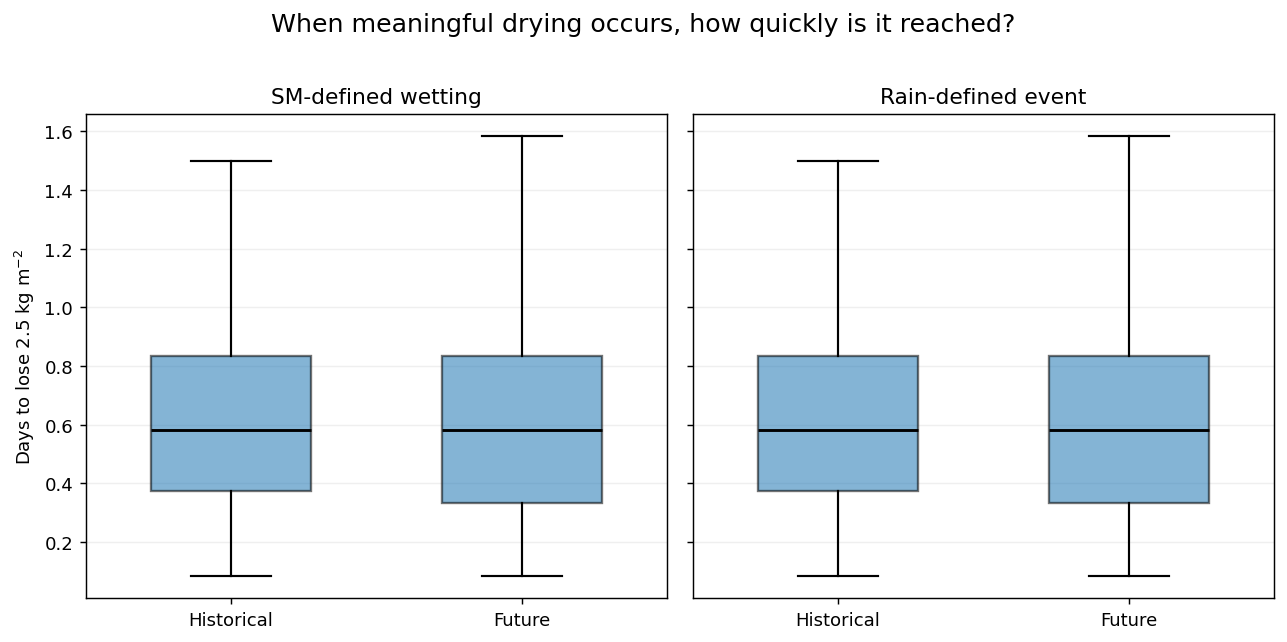

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), dpi=130, sharey=True)

for ax, definition, title in zip(
    axes,
    DEFS,
    ["SM-defined wetting", "Rain-defined event"]
):
    h = reached[
        (reached["definition"] == definition) &
        (reached["label"] == "hist")
    ]["days_to_dry_2p5"].dropna()

    f = reached[
        (reached["definition"] == definition) &
        (reached["label"] == "future")
    ]["days_to_dry_2p5"].dropna()

    bp = ax.boxplot(
        [h, f],
        positions=[1, 2],
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.6},
        boxprops={"linewidth": 1.3},
        whiskerprops={"linewidth": 1.2},
        capprops={"linewidth": 1.2},
    )

    for patch in bp["boxes"]:
        patch.set_alpha(0.55)

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["Historical", "Future"])
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel(
    r"Days to lose 2.5 kg m$^{-2}$"
)

fig.suptitle(
    "When meaningful drying occurs, how quickly is it reached?",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

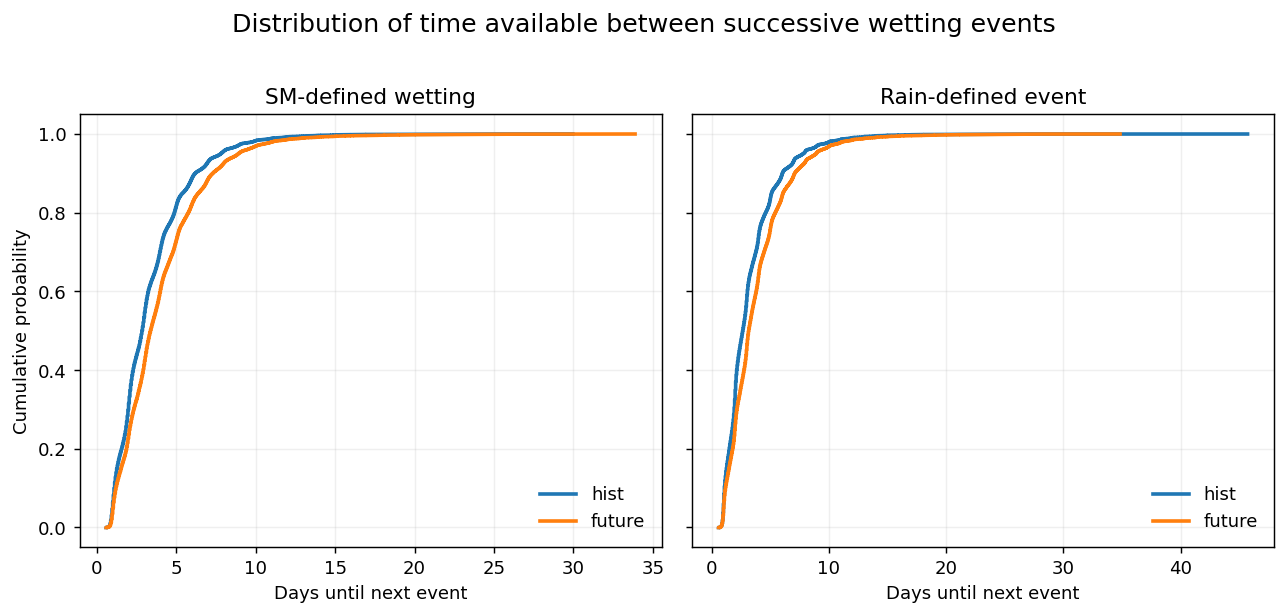

In [16]:
def plot_cdf(ax, vals, label):
    vals = np.sort(np.asarray(vals))
    vals = vals[np.isfinite(vals)]

    if len(vals) == 0:
        return

    y = np.arange(1, len(vals)+1) / len(vals)
    ax.plot(vals, y, lw=2, label=label)


fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), dpi=130, sharey=True)

for ax, definition, title in zip(
    axes,
    DEFS,
    ["SM-defined wetting", "Rain-defined event"]
):
    for label in ["hist", "future"]:
        vals = inter[
            (inter["definition"] == definition) &
            (inter["label"] == label)
        ]["days_to_next_event"]

        plot_cdf(ax, vals, label)

    ax.set_title(title)
    ax.set_xlabel("Days until next event")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)

axes[0].set_ylabel("Cumulative probability")

fig.suptitle(
    "Distribution of time available between successive wetting events",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

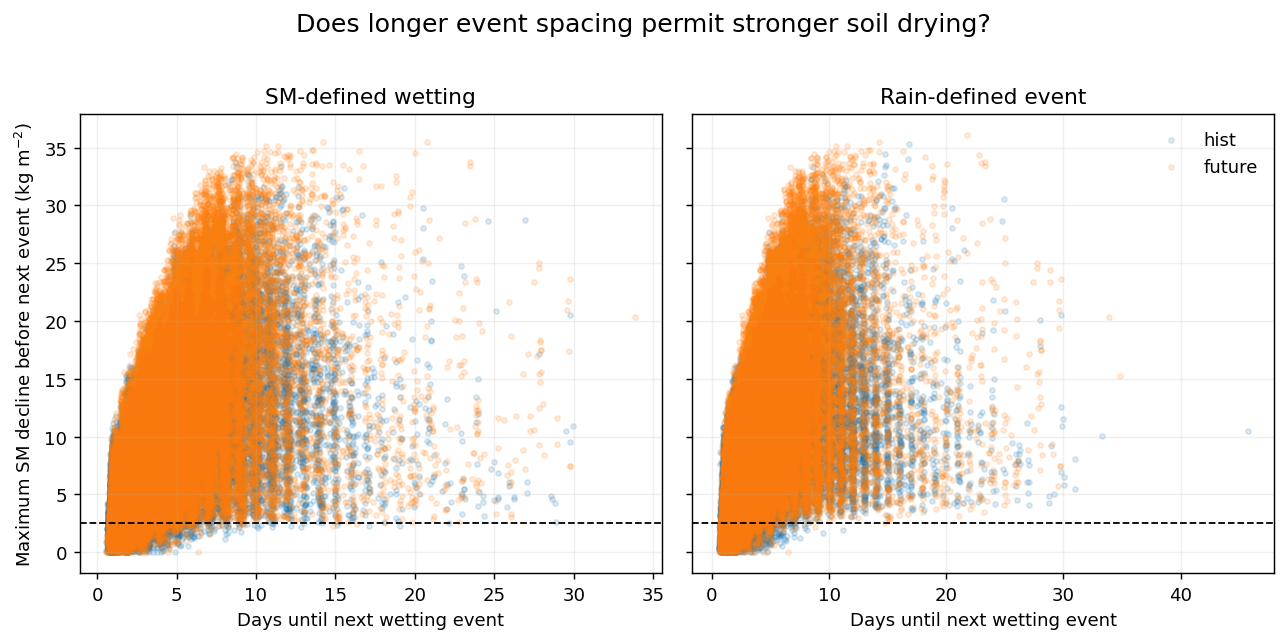

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), dpi=130, sharey=True)

for ax, definition, title in zip(
    axes,
    DEFS,
    ["SM-defined wetting", "Rain-defined event"]
):
    for label in ["hist", "future"]:
        s = dry[
            (dry["definition"] == definition) &
            (dry["label"] == label)
        ]

        ax.scatter(
            s["hours_to_next_event"] / 24,
            s["max_drydown"],
            s=8,
            alpha=0.15,
            label=label,
        )

    ax.axhline(2.5, color="k", ls="--", lw=1)
    ax.set_xlabel("Days until next wetting event")
    ax.set_title(title)
    ax.grid(alpha=0.2)

axes[0].set_ylabel(
    r"Maximum SM decline before next event (kg m$^{-2}$)"
)

axes[1].legend(frameon=False)

fig.suptitle(
    "Does longer event spacing permit stronger soil drying?",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

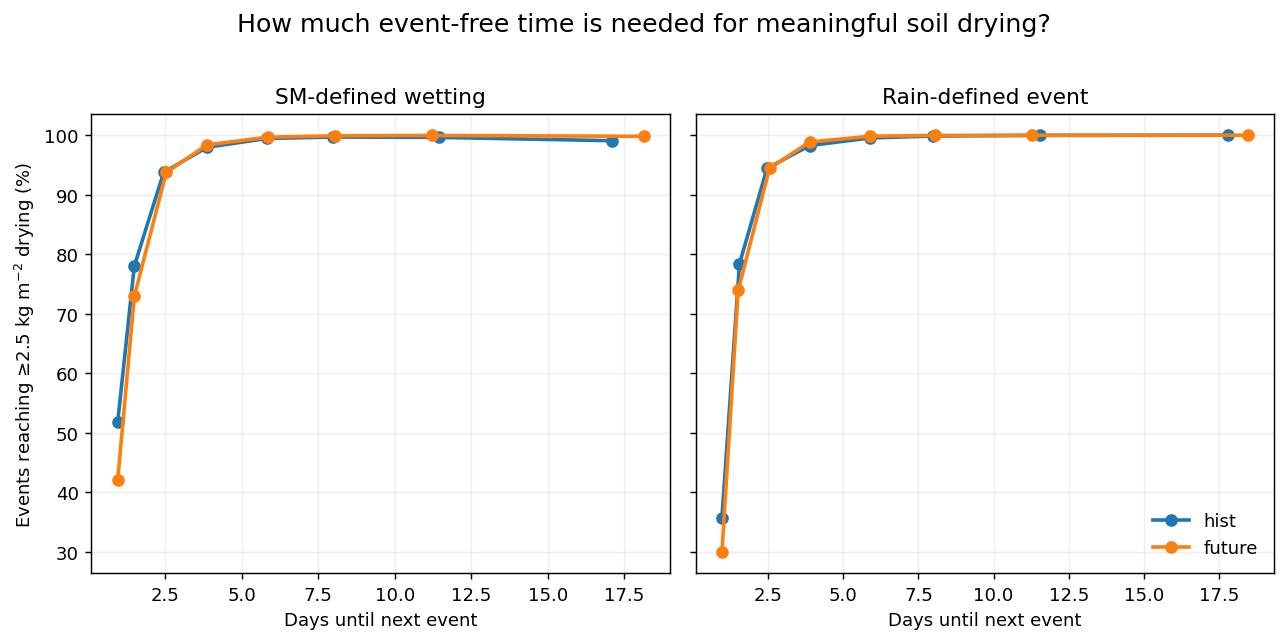

In [18]:
day_bins = [0, 0.5, 1, 2, 3, 5, 7, 10, 15, 30]

dry["days_to_next_event"] = dry["hours_to_next_event"] / 24
dry["spacing_bin"] = pd.cut(
    dry["days_to_next_event"],
    day_bins,
    include_lowest=True
)

spacing_dry = (
    dry.groupby(
        ["label", "definition", "spacing_bin"],
        observed=True
    )
    .agg(
        days=("days_to_next_event", "median"),
        probability=("drydown_ge_2p5", "mean"),
        n=("drydown_ge_2p5", "size"),
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), dpi=130, sharey=True)

for ax, definition, title in zip(
    axes,
    DEFS,
    ["SM-defined wetting", "Rain-defined event"]
):
    for label in ["hist", "future"]:
        s = spacing_dry[
            (spacing_dry["definition"] == definition) &
            (spacing_dry["label"] == label) &
            (spacing_dry["n"] >= 20)
        ]

        ax.plot(
            s["days"],
            s["probability"] * 100,
            marker="o",
            lw=2,
            label=label,
        )

    ax.set_xlabel("Days until next event")
    ax.set_title(title)
    ax.grid(alpha=0.2)

axes[0].set_ylabel(
    r"Events reaching ≥2.5 kg m$^{-2}$ drying (%)"
)

axes[1].legend(frameon=False)

fig.suptitle(
    "How much event-free time is needed for meaningful soil drying?",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

In [19]:
summary = []

for definition in DEFS:
    for label in LABELS:

        s = dry[
            (dry["definition"] == definition) &
            (dry["label"] == label)
        ]

        reached_s = s[s["drydown_ge_2p5"]]

        summary.append({
            "definition": definition,
            "climate": label,
            "n_intervals": len(s),

            "median_event_spacing_d":
                np.nanmedian(s["hours_to_next_event"] / 24),

            "median_max_drydown":
                np.nanmedian(s["max_drydown"]),

            "fraction_drying_ge2p5":
                np.nanmean(s["drydown_ge_2p5"]) * 100,

            "median_days_to_dry2p5":
                np.nanmedian(reached_s["days_to_dry_2p5"])
                if len(reached_s) else np.nan,
        })

summary = pd.DataFrame(summary)
display(summary.round(2))

,definition,climate,n_intervals,median_event_spacing_d,median_max_drydown,fraction_drying_ge2p5,median_days_to_dry2p5
0,SM>=2.5,hist,146641,2.83,6.50,89.28,0.58
1,SM>=2.5,future,90564,3.38,8.08,90.35,0.58
2,Rain>=5mm,hist,149240,2.67,6.29,88.04,0.58
3,Rain>=5mm,future,93554,3.17,7.84,89.45,0.58


In [20]:
# thresholds = [2.5, 5, 7.5, 10, 12.5]

# rows = []

# for definition in DEFS:
#     for label in ["hist", "future"]:
#         s = dry[
#             (dry["definition"] == definition) &
#             (dry["label"] == label)
#         ]

#         for threshold in thresholds:
#             rows.append({
#                 "definition": definition,
#                 "label": label,
#                 "threshold": threshold,
#                 "fraction": np.mean(s["max_drydown"] >= threshold) * 100,
#             })

# dry_thresh = pd.DataFrame(rows)

# display(dry_thresh)

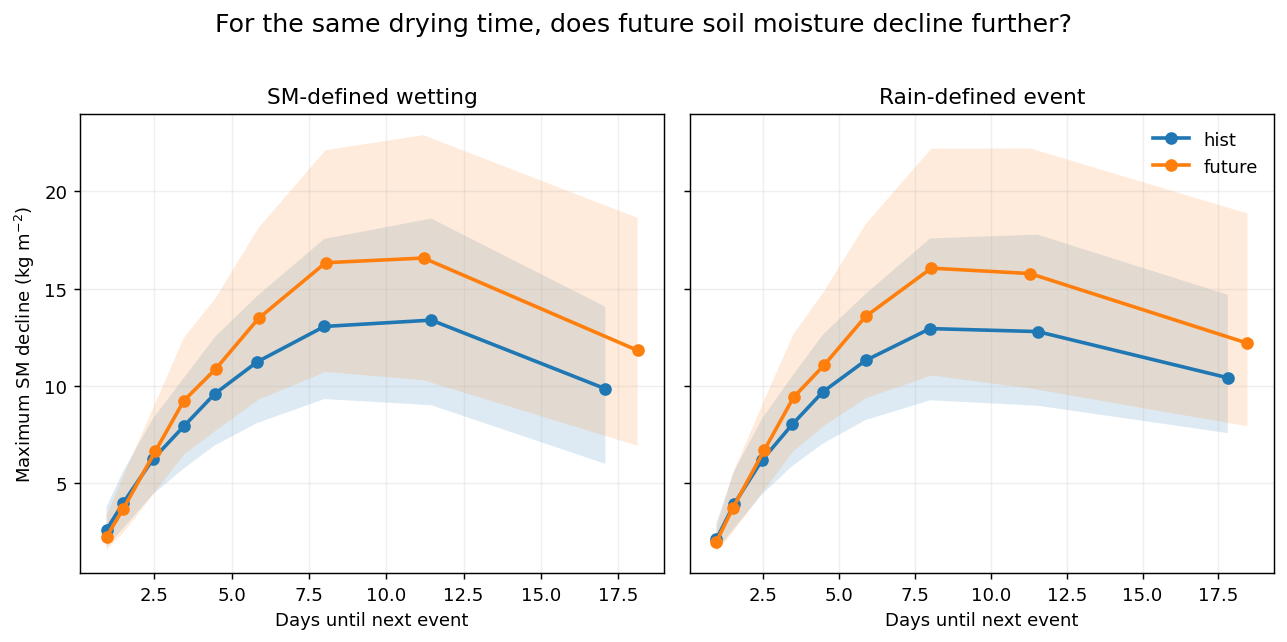

In [21]:
bins = [0.5, 1, 2, 3, 4, 5, 7, 10, 15, 30]

tmp = dry.copy()
tmp["days"] = tmp["hours_to_next_event"] / 24
tmp["spacing_bin"] = pd.cut(tmp["days"], bins=bins)

cond = (
    tmp.groupby(["definition", "label", "spacing_bin"], observed=True)
    .agg(
        days=("days", "median"),
        dry_median=("max_drydown", "median"),
        dry_p25=("max_drydown", lambda x: np.nanpercentile(x, 25)),
        dry_p75=("max_drydown", lambda x: np.nanpercentile(x, 75)),
        n=("max_drydown", "size"),
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), dpi=130, sharey=True)

for ax, definition, title in zip(
    axes, DEFS,
    ["SM-defined wetting", "Rain-defined event"]
):
    for label in ["hist", "future"]:
        s = cond[
            (cond["definition"] == definition) &
            (cond["label"] == label) &
            (cond["n"] >= 50)
        ]

        ax.plot(
            s["days"], s["dry_median"],
            marker="o", lw=2, label=label
        )

        ax.fill_between(
            s["days"], s["dry_p25"], s["dry_p75"],
            alpha=0.15
        )

    ax.set_xlabel("Days until next event")
    ax.set_title(title)
    ax.grid(alpha=0.2)

axes[0].set_ylabel(r"Maximum SM decline (kg m$^{-2}$)")
axes[1].legend(frameon=False)

fig.suptitle(
    "For the same drying time, does future soil moisture decline further?",
    fontsize=14, y=1.02
)

plt.tight_layout()
plt.show()

In [22]:
c = cond[
    cond["n"] >= 50
].pivot_table(
    index=["definition", "spacing_bin"],
    columns="label",
    values=["days", "dry_median"]
).reset_index()

c["dry_FminusH"] = (
    c[("dry_median", "future")] -
    c[("dry_median", "hist")]
)

display(c[[
    ("definition", ""),
    ("spacing_bin", ""),
    ("days", "hist"),
    ("dry_median", "hist"),
    ("dry_median", "future"),
    ("dry_FminusH", ""),
]])

definition   spacing_bin       days dry_median            dry_FminusH
label                                hist       hist     future            
0      Rain>=5mm    (0.5, 1.0]   0.958333   2.087780   1.958274   -0.129506
1      Rain>=5mm    (1.0, 2.0]   1.541667   3.894531   3.693127   -0.201405
2      Rain>=5mm    (2.0, 3.0]   2.458333   6.154003   6.693588    0.539585
3      Rain>=5mm    (3.0, 4.0]   3.458333   8.001396   9.397760    1.396364
4      Rain>=5mm    (4.0, 5.0]   4.458333   9.666613  11.043266    1.376653
5      Rain>=5mm    (5.0, 7.0]   5.875000  11.296796  13.563815    2.267019
6      Rain>=5mm   (7.0, 10.0]   8.000000  12.936667  16.050938    3.114272
7      Rain>=5mm  (10.0, 15.0]  11.541667  12.784086  15.772863    2.988777
8      Rain>=5mm  (15.0, 30.0]  17.812500  10.402201  12.184302    1.782100
9        SM>=2.5    (0.5, 1.0]   0.958333   2.570919   2.219505   -0.351414
10       SM>=2.5    (1.0, 2.0]   1.500000   3.963612   3.649699   -0.313912
11       SM>=2.5    (2.0, 3.0]   2.458333   6.204895   6.634345    0.429450
12       SM>=2.5    (3.0, 4.0]   3.458333   7.906200   9.221314    1.315114
13       SM>=2.5    (4.0, 5.0]   4.458333   9.578475  10.880229    1.301754
14       SM>=2.5    (5.0, 7.0]   5.833333  11.225274  13.465228    2.239954
15       SM>=2.5   (7.0, 10.0]   8.000000  13.047357  16.331375    3.284018
16       SM>=2.5  (10.0, 15.0]  11.458333  13.373227  16.571855    3.198628
17       SM>=2.5  (15.0, 30.0]  17.083333   9.837875  11.814567    1.976692

In [23]:
tmp["effective_drying_rate"] = (
    tmp["max_drydown"] / tmp["days"]
)

display(
    tmp.groupby(["definition", "label"])["effective_drying_rate"]
       .agg(["count", "mean", "median"])
)

count      mean    median
definition label                             
Rain>=5mm  future   93554  2.602246  2.421207
           hist    149240  2.477550  2.297009
SM>=2.5    future   90564  2.575229  2.412076
           hist    146641  2.484107  2.304749

/tmp/ipykernel_21949/530733103.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_21949/530733103.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


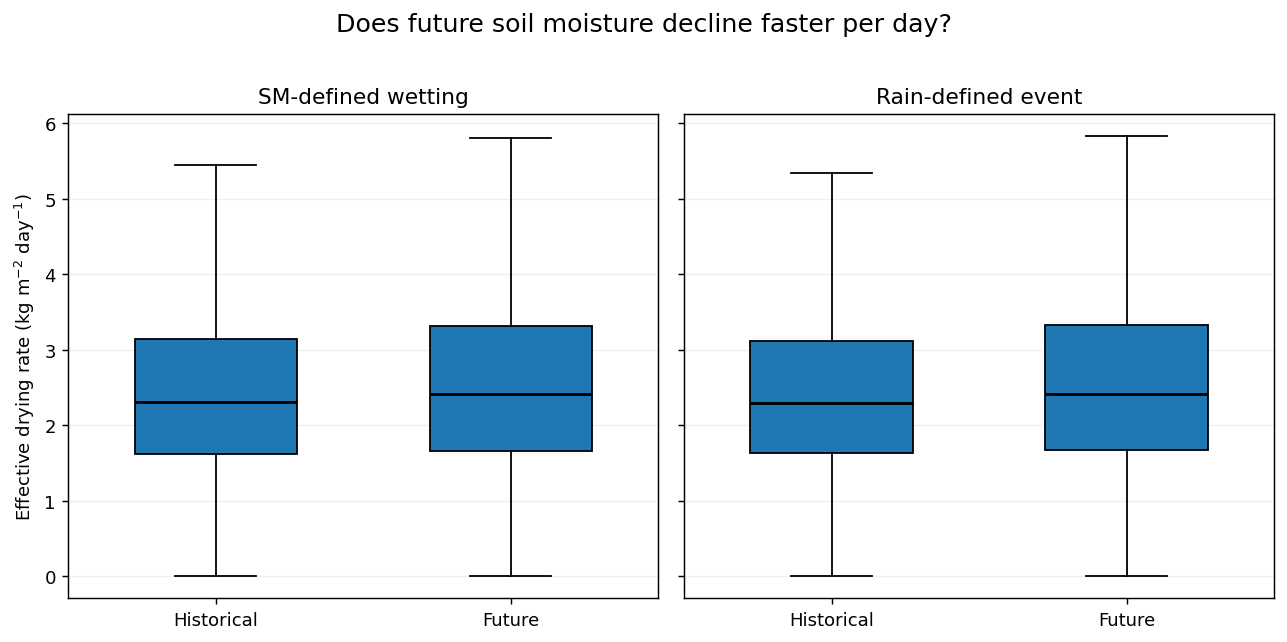

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), dpi=130, sharey=True)

for ax, definition, title in zip(
    axes, DEFS,
    ["SM-defined wetting", "Rain-defined event"]
):
    vals = [
        tmp[
            (tmp["definition"] == definition) &
            (tmp["label"] == "hist")
        ]["effective_drying_rate"].dropna(),

        tmp[
            (tmp["definition"] == definition) &
            (tmp["label"] == "future")
        ]["effective_drying_rate"].dropna()
    ]

    ax.boxplot(
        vals,
        labels=["Historical", "Future"],
        showfliers=False,
        widths=0.55,
        patch_artist=True,
        medianprops={"color": "black", "linewidth": 1.6}
    )

    ax.set_title(title)
    ax.grid(axis="y", alpha=0.2)

axes[0].set_ylabel(r"Effective drying rate (kg m$^{-2}$ day$^{-1}$)")

fig.suptitle(
    "Does future soil moisture decline faster per day?",
    fontsize=14, y=1.02
)

plt.tight_layout()
plt.show()